# Gold — Fraud Risk Analysis & Reporting

## Project Objective

Analyze the prepared Silver dataset to evaluate fraud risk patterns, measure the effectiveness of transaction review strategies, and develop business-ready insights.

### Key Business Questions

1. Which transaction types present the highest fraud risk?
2. How effectively do our risk indicators identify fraudulent transactions?
3. How many transactions would require investigation under different risk strategies?
4. What are the trade-offs between detecting fraud and reducing investigation workload?

### Data Source

Prepared Silver dataset: `paysim_silver.csv`

### Analytical Approach

Use Python and pandas to aggregate transaction data, calculate fraud detection KPIs, compare risk strategies, and prepare reporting-ready outputs.

In [1]:
import pandas as pd

In [2]:
import pandas as pd

df = pd.read_csv("../data/paysim_silver.csv")

In [3]:
df.shape

(6362620, 14)

In [4]:
df["isFraud"].sum()

np.int64(8213)

In [5]:
df["isFraud"].mean() * 100

np.float64(0.12908204481801522)

### KPI 1 — Overall Fraud Rate

**Objective:** Measure the proportion of fraudulent transactions in the dataset.

**Results:**
- Total transactions: 6,362,620
- Fraudulent transactions: 8,213
- Overall fraud rate: 0.1291%

**Business Interpretation:**

Fraudulent transactions represent approximately 0.13% of all transactions, indicating a highly imbalanced dataset.

Because fraud is rare, identifying fraudulent transactions while minimizing unnecessary investigations is an important challenge.

Accuracy alone may be misleading when evaluating fraud detection strategies. Precision and recall provide more useful information about detection performance.

In [6]:
df.groupby("type")["isFraud"].mean()*100

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64

### KPI 2 — Fraud Rate by Transaction Type

**Objective:** Identify which transaction types have the highest proportion of fraudulent transactions.

**Results:**

| Transaction Type | Fraud Rate |
|---|---:|
| TRANSFER | 0.7688% |
| CASH_OUT | 0.1840% |
| CASH_IN | 0.0000% |
| DEBIT | 0.0000% |
| PAYMENT | 0.0000% |

**Key Findings:**

- TRANSFER transactions have the highest fraud rate at approximately 0.77%.
- CASH_OUT transactions have the second-highest fraud rate at approximately 0.18%.
- No fraudulent transactions were recorded for CASH_IN, DEBIT, or PAYMENT in this dataset.
- Although CASH_OUT has slightly more recorded fraud cases (4,116) than TRANSFER (4,097), TRANSFER has a higher fraud rate relative to its transaction volume.

**Business Interpretation:**

TRANSFER transactions should be prioritized for risk-based investigation because they have the highest observed fraud rate.

However, CASH_OUT transactions also require attention because they account for slightly more recorded fraud cases.

A risk-based investigation strategy should consider both fraud rates and transaction volumes to balance fraud detection with operational workload.

**Limitations:**

These findings are based on simulated transaction data. The observed fraud rates should not be assumed to represent real-world banking activity.

### KPI 3 — Investigation Workload by Risk Strategy

**Objective:** Compare the number of transactions flagged for investigation under two risk-based screening strategies.

**Business Question:** Which strategy reduces investigation workload while maintaining effective fraud detection?

In [7]:
df["high_risk_type_flag"].sum()

np.int64(2770409)

In [8]:
df["combined_risk_flag"].sum()

np.int64(1934297)

In [9]:
df["high_risk_type_flag"].sum() - df["combined_risk_flag"].sum()

np.int64(836112)

In [10]:
(df["high_risk_type_flag"].sum() - df["combined_risk_flag"].sum())/df["high_risk_type_flag"].sum()*100

np.float64(30.180092542292492)

### KPI 3 — Investigation Workload Reduction

**Objective:** Compare the investigation workload generated by two fraud screening strategies.

**Results:**

| Metric | Strategy A: High-Risk Type | Strategy B: Combined Risk |
|---|---:|---:|
| Transactions flagged | 2,770,409 | 1,934,297 |
| Fraud cases detected | 8,213 | 6,506 |
| Recall | 100.00% | 79.22% |

**Workload Reduction:**
- Transactions removed from the investigation queue: 836,112
- Percentage reduction: 30.18%

**Business Interpretation:**

The combined risk strategy reduces the potential investigation workload by approximately 30.18% compared with the transaction-type strategy.

However, this reduction comes with an important trade-off: Strategy B fails to flag 1,707 fraudulent transactions that Strategy A would have identified.

Although Strategy B improves operational efficiency by reducing the number of transactions requiring review, its lower recall introduces additional fraud detection risk.

**Conclusion:**

The preferred strategy depends on the organization's investigation capacity, risk tolerance, and the potential financial impact of missed fraud. Further evaluation is needed before recommending either strategy for operational use.

#### KPI 4 Calculating Precision and Recall for Strategy A 

In [11]:
df.groupby("high_risk_type_flag")["isFraud"].sum()

high_risk_type_flag
0       0
1    8213
Name: isFraud, dtype: int64

In [12]:
8213 / 2770409 *100

0.2964544224336551

#### KPI 4 Calculating Precision and Recall for Strategy B

In [13]:
df.groupby("combined_risk_flag")["isFraud"].sum()

combined_risk_flag
0    1707
1    6506
Name: isFraud, dtype: int64

In [14]:
6506/1934297*100

0.33634958850683216

In [15]:
6506/8213*100

79.21587726774627

### KPI 4 — Fraud Detection Performance: Precision and Recall

**Objective:** Evaluate and compare the effectiveness of two fraud screening strategies using precision and recall.

**Results:**

| Metric | Strategy A: High-Risk Type | Strategy B: Combined Risk |
|---|---:|---:|
| True Positives (TP) | 8,213 | 6,506 |
| False Negatives (FN) | 0 | 1,707 |
| Precision | 0.2965% | 0.3363% |
| Recall | 100.00% | 79.22% |
| Transactions Flagged | 2,770,409 | 1,934,297 |

**Key Findings:**

- Strategy A detected all 8,213 recorded fraudulent transactions, achieving 100% recall.
- Strategy B detected 6,506 fraudulent transactions, achieving 79.22% recall.
- Strategy B improved precision slightly, from 0.2965% to 0.3363%.
- Strategy B reduced investigation workload by 30.18% but missed 1,707 additional fraudulent transactions.

**Business Interpretation:**

The results demonstrate a trade-off between investigation efficiency and fraud detection effectiveness.

Strategy A prioritizes fraud detection but generates a large investigation workload.

Strategy B reduces the number of transactions requiring investigation, but its lower recall introduces additional risk from undetected fraud.

The modest improvement in precision may not justify the loss in recall, depending on the financial impact of missed fraud and the organization's risk tolerance.

**Limitations:**

Both strategies are exploratory rules evaluated on the same simulated dataset used to develop them. Their performance has not been validated on independent data, and these results should not be interpreted as real-world operational performance.

**Conclusion:**

Neither strategy should be deployed without further evaluation. Future analysis should consider the financial value of detected and missed fraud, investigation capacity, and alternative risk thresholds.

### KPI 5 — Financial Exposure from Fraudulent Transactions

**Objective:** Measure the total monetary value of recorded fraudulent transactions and evaluate the financial exposure associated with missed fraud.

**Business Questions:**

1. What is the total value of fraudulent transactions?
2. How much fraudulent transaction value does each screening strategy flag?
3. What is the total value of fraudulent transactions missed by Strategy B?

**Important:** Transaction amounts represent potential financial exposure, not necessarily confirmed financial losses.

In [16]:
df.groupby("isFraud")["amount"].sum().round(2)

isFraud
0    1.132337e+12
1    1.205642e+10
Name: amount, dtype: float64

In [17]:
df.groupby("isFraud")["amount"].sum().map("{:,.2f}".format)

isFraud
0    1,132,336,529,331.93
1       12,056,415,427.84
Name: amount, dtype: str

In [18]:
df[
    (df["isFraud"] == 1) &
    (df["combined_risk_flag"] == 0)
]["amount"].sum()

np.float64(73020052.09)

### KPI 5 — Financial Exposure from Fraudulent Transactions

**Objective:** Evaluate the total monetary value of fraudulent transactions and the potential exposure associated with fraud cases missed by Strategy B.

**Results:**

| Metric | Transaction Value |
|---|---:|
| Total legitimate transaction value | 1,132,336,529,331.93 |
| Total fraudulent transaction value | 12,056,415,427.84 |
| Fraudulent transaction value missed by Strategy B | 73,020,052.09 |
| Fraudulent transactions missed by Strategy B | 1,707 |

**Key Findings:**

- The dataset contains approximately 12.06 billion in fraudulent transaction value.
- Strategy B failed to flag 1,707 fraudulent transactions with a combined value of approximately 73.02 million.
- Reducing investigation workload introduces a trade-off between operational efficiency and fraud detection.

**Business Interpretation:**

Transaction counts alone do not fully describe financial risk. The monetary value associated with detected and missed fraud should also be considered when evaluating screening strategies.

Although Strategy B misses a substantial number of fraudulent transactions, further analysis is required to determine what percentage of total fraudulent transaction value these cases represent.

**Limitations:**

The PaySim dataset contains simulated transaction amounts. Fraudulent transaction value represents potential exposure, not confirmed financial losses or recoverable funds.

**Next Step:**

Calculate the percentage of total fraudulent transaction value captured by each strategy.

### KPI 6 — Financial Risk Coverage

**Objective:** Measure the percentage of total fraudulent transaction value captured by each fraud screening strategy.

**Business Question:** How much fraudulent transaction value does Strategy B identify compared with Strategy A?

**Metric Definition:**

Financial Risk Coverage (%) = (Flagged Fraudulent Transaction Value / Total Fraudulent Transaction Value) × 100

In [19]:
detected_fraud_value = 12056415427.84 - 73020052.09
print(detected_fraud_value)

11983395375.75


In [20]:
financial_coverage = (11983395375.75 / 12056415427.84) * 100
print(financial_coverage)

99.3943469140804


### KPI 6 — Financial Risk Coverage: Results and Interpretation

**Objective:** Evaluate the percentage of fraudulent transaction value identified by each screening strategy.

**Results:**

| Metric | Strategy A | Strategy B |
|---|---:|---:|
| Financial Risk Coverage | 100% | 99.39% |
| Fraud Recall | 100% | 79.22% |
| Investigation Workload | 2,770,409 | 1,934,297 |
| Missed Fraudulent Transactions | 0 | 1,707 |
| Missed Fraudulent Transaction Value | 0 | 73,020,052.09 |

**Key Findings:**

Strategy B reduces the investigation workload by 30.18% while identifying approximately 99.39% of the total fraudulent transaction value.

Although Strategy B misses 20.78% of fraudulent transactions, those transactions represent only 0.61% of the total fraudulent transaction value.

**Business Interpretation:**

These findings suggest that Strategy B prioritizes transactions associated with higher monetary exposure, potentially improving investigation efficiency.

However, Strategy B still misses 1,707 fraudulent transactions and has a low precision rate of approximately 0.34%, indicating a high number of false positives.

**Conclusion:**

Financial Risk Coverage complements Fraud Recall by measuring the monetary value associated with detected fraud rather than only the number of fraudulent transactions.

Strategy B demonstrates promising financial coverage, but further testing and refinement are necessary before operational implementation.

**Limitations:**

The PaySim dataset is simulated. Transaction amounts represent potential financial exposure, not confirmed financial losses. The risk threshold was selected for exploratory analysis and has not been independently validated.

## Gold — Data Visualizations

### Visualization 1 — Fraud Rate by Transaction Type

**Objective:** Compare fraud rates across transaction types to identify higher-risk categories.

In [21]:
fraud_rate_by_type = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate_by_type)

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


In [22]:
import matplotlib.pyplot as plt

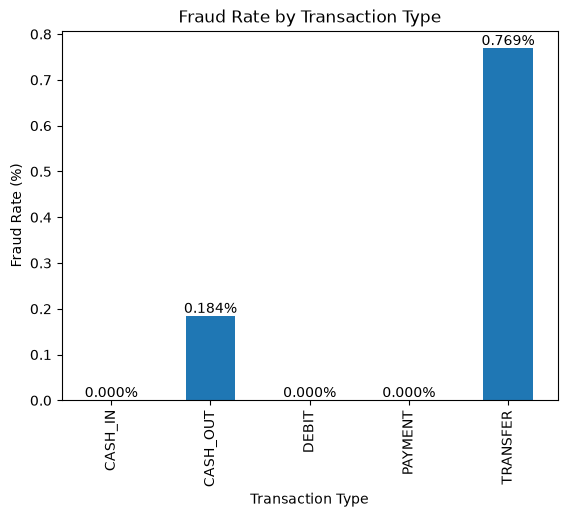

In [23]:
ax = fraud_rate_by_type.plot(kind="bar")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.3f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.show()

### Visualization 1 — Fraud Rate by Transaction Type

**Objective:** Compare fraud rates across transaction types to identify higher-risk categories.

**Key Findings:**

- TRANSFER has the highest fraud rate at 0.769%.
- CASH_OUT has the second-highest fraud rate at 0.184%.
- CASH_IN, DEBIT, and PAYMENT have no recorded fraudulent transactions in this dataset.

**Business Interpretation:**

TRANSFER and CASH_OUT transactions represent the highest-risk categories based on observed fraud rates.

These findings support prioritizing these transaction types for further fraud risk analysis and investigation.

**Conclusion:**

Fraud risk varies significantly across transaction types. Transaction type is a useful indicator for developing an initial fraud screening strategy, although it is not sufficient on its own to accurately identify fraudulent transactions.

### Visualization 2 — Investigation Workload Comparison

**Objective:** Compare the investigation workload generated by Strategy A and Strategy B.

In [24]:
strategies = ["Strategy A", "Strategy B"]
workload = [2770409, 1934297]

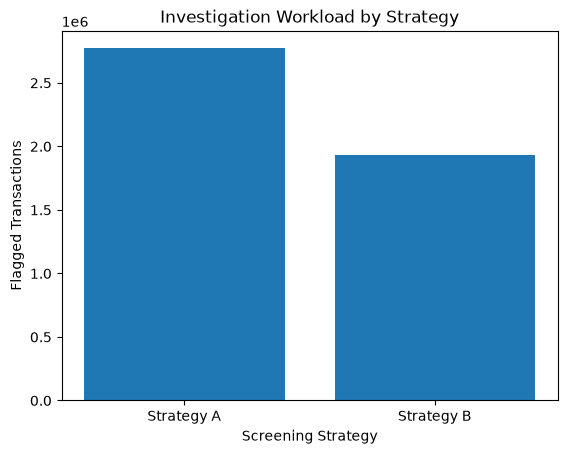

In [25]:
plt.bar(strategies, workload)

plt.title("Investigation Workload by Strategy")
plt.xlabel("Screening Strategy")
plt.ylabel("Flagged Transactions")

plt.show()

### Visualization 2 — Investigation Workload Comparison

**Objective:** Compare the number of transactions flagged for investigation by Strategy A and Strategy B.

**Key Findings:**

- **Strategy A:** 2,770,409 transactions flagged.
- **Strategy B:** 1,934,297 transactions flagged.
- **Workload Reduction:** 836,112 transactions (30.18%).

**Business Interpretation:**

Strategy B reduces the potential investigation workload by approximately 30%, allowing investigators to focus on a smaller number of transactions.

However, this efficiency improvement comes with a trade-off: Strategy B misses 1,707 fraudulent transactions that Strategy A would flag.

**Conclusion:**

Strategy B offers a significant reduction in investigation workload, but operational efficiency must be balanced against fraud detection performance.

Further refinement is needed to reduce false positives and minimize missed fraud.

In [26]:
metrics = ["Fraud Recall", "Financial Risk Coverage"]
strategy_b = [79.22, 99.39]

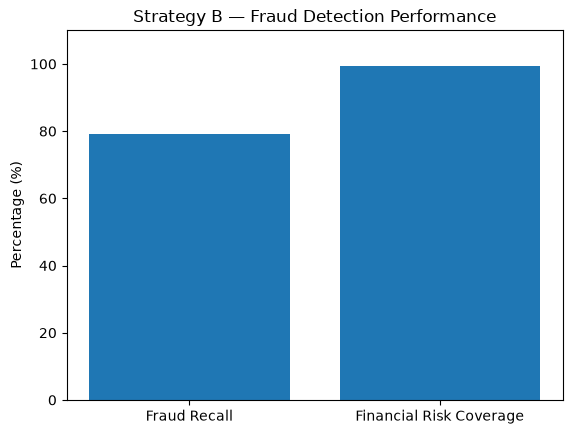

In [27]:
plt.bar(metrics, strategy_b)

plt.title("Strategy B — Fraud Detection Performance")
plt.ylabel("Percentage (%)")
plt.ylim(0, 110)

plt.show()

### Visualization 3 — Fraud Recall vs. Financial Risk Coverage

**Objective:** Compare the percentage of fraudulent transactions detected by Strategy B with the percentage of fraudulent transaction value captured.

**Key Findings:**

- **Fraud Recall:** 79.22%
- **Financial Risk Coverage:** 99.39%
- **Missed Fraudulent Transactions:** 1,707
- **Missed Fraudulent Transaction Value:** 73,020,052.09

**Business Interpretation:**

Strategy B identifies approximately 79% of fraudulent transactions while capturing more than 99% of their total monetary value.

This indicates that the missed fraudulent transactions generally have lower monetary values than the detected ones.

However, high financial coverage does not eliminate the risk associated with missed fraudulent transactions.

**Conclusion:**

Evaluating fraud detection strategies requires considering both transaction-level recall and financial risk coverage. Strategy B demonstrates strong monetary coverage but requires further improvement in fraud detection accuracy.

**Limitations:**

The analysis uses simulated transaction values. Financial risk coverage does not represent actual financial losses prevented.

### Visualization 4 — Financial Impact: Strategy A vs. Strategy B

**Objective:** Compare the financial risk coverage and investigation workload of two fraud screening strategies.

**Key Findings:**

| Metric | Strategy A | Strategy B |
|---|---:|---:|
| Fraudulent Value Detected | 12.06 billion | 11.98 billion |
| Fraudulent Value Missed | 0 | 73.02 million |
| Financial Risk Coverage | 100% | 99.39% |
| Transactions Flagged | 2,770,409 | 1,934,297 |

**Business Insight:**

Strategy A identifies all recorded fraudulent transaction value but requires investigating 836,112 additional transactions compared with Strategy B.

Strategy B reduces the investigation workload by 30.18% while maintaining 99.39% financial risk coverage. However, it leaves 1,707 fraudulent transactions unflagged, representing approximately 73.02 million in simulated transaction value.

**Recommendation:**

Neither strategy should be deployed without further validation. Strategy A provides stronger fraud detection coverage, while Strategy B offers greater operational efficiency.

Future improvements should focus on reducing false positives while maintaining high fraud recall and financial risk coverage.

**Limitation:** Transaction values are simulated and do not represent confirmed financial losses.

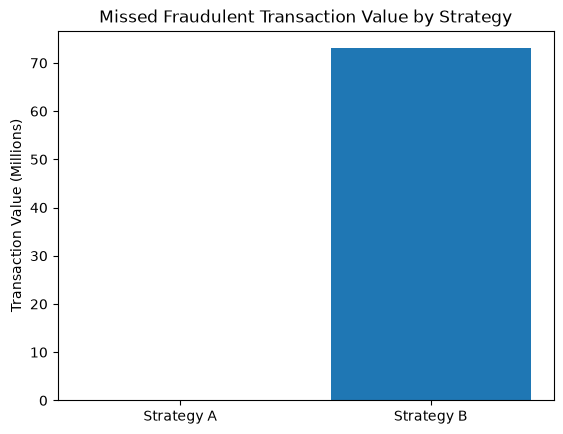

In [28]:
strategies = ["Strategy A", "Strategy B"]
missed_amounts = [0, 73.02]

plt.bar(strategies, missed_amounts)

plt.title("Missed Fraudulent Transaction Value by Strategy")
plt.ylabel("Transaction Value (Millions)")

plt.show()

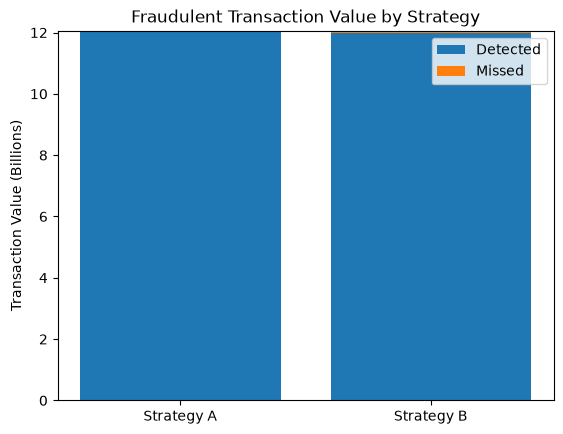

In [29]:
import matplotlib.pyplot as plt

strategies = ["Strategy A", "Strategy B"]

detected = [12.0564, 11.9834]
missed = [0, 0.07302]

plt.bar(strategies, detected, label="Detected")
plt.bar(strategies, missed, bottom=detected, label="Missed")

plt.title("Fraudulent Transaction Value by Strategy")
plt.ylabel("Transaction Value (Billions)")
plt.legend()

plt.show()

In [30]:
display(
    comparison.style.format({
        "Strategy A": "{:,.2f}",
        "Strategy B": "{:,.2f}"
    })
)

NameError: name 'comparison' is not defined

### Visualization 4 — Financial Impact: Strategy A vs. Strategy B

**Objective:** Compare the financial risk coverage and investigation workload of two fraud screening strategies.

**Key Findings:**

- Strategy A identifies 100% of recorded fraudulent transaction value.
- Strategy B identifies 99.39% of fraudulent transaction value.
- Strategy B reduces investigation workload by 30.18%, equivalent to 836,112 fewer transactions flagged.
- Strategy B misses 1,707 fraudulent transactions, representing 73.02 million in simulated transaction value.

**Business Interpretation:**

Strategy A provides stronger fraud detection coverage but requires substantially more investigations.

Strategy B improves operational efficiency while maintaining high monetary coverage. However, the missed fraudulent transactions and low precision remain important concerns.

**Recommendation:**

Neither strategy is ready for operational deployment without further validation. Future improvements should focus on reducing false positives while maintaining high fraud recall and financial risk coverage.

**Limitations:**

The analysis uses simulated transaction values. Financial exposure does not represent confirmed financial losses.

## Business Recommendations & Final Conclusions

### Key Findings

The analysis evaluated two fraud screening strategies using 6,362,620 simulated financial transactions.

- **Strategy A:** Achieved 100% fraud recall but flagged 2,770,409 transactions for investigation.
- **Strategy B:** Reduced investigation workload by 30.18%, while maintaining 79.22% fraud recall.
- **Financial Coverage:** Strategy B captured 99.39% of fraudulent transaction value but missed 1,707 fraudulent transactions worth approximately 73.02 million.
- **Precision:** Both strategies demonstrated very low precision, indicating substantial false-positive investigation workloads.

### Business Recommendations

1. **Prioritize fraud detection:** Consider Strategy A as a conservative screening baseline when minimizing missed fraud is the primary objective.
2. **Improve investigation efficiency:** Explore additional transaction characteristics to reduce false positives and unnecessary investigations.
3. **Evaluate financial exposure:** Monitor both fraud recall and financial risk coverage when comparing screening strategies.
4. **Validate before deployment:** Test alternative thresholds and screening rules on separate evaluation data before making operational decisions.

### Final Conclusion

The analysis demonstrates that fraud screening involves trade-offs between detection performance, financial exposure, and operational efficiency.

Although Strategy B reduces investigation workload and maintains high monetary coverage, neither strategy is ready for production without further validation.

**Limitations:** PaySim contains simulated transactions. Results are exploratory and do not represent actual financial losses or verified real-world screening performance.